<a href="https://colab.research.google.com/github/Thrisha213/4NI25CS213_DAV_LAB/blob/main/4NI25CS213_EXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/House_Price_dataset (1).csv')
df = df[df['purpose'] == 'For Sale']
df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()

In [4]:
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [5]:
df = df.sample(n=100, random_state=42).reset_index(drop=True)

In [7]:
X = df[['price', 'bedrooms', 'baths', 'Area Size']]
X_scaled = StandardScaler().fit_transform(X)

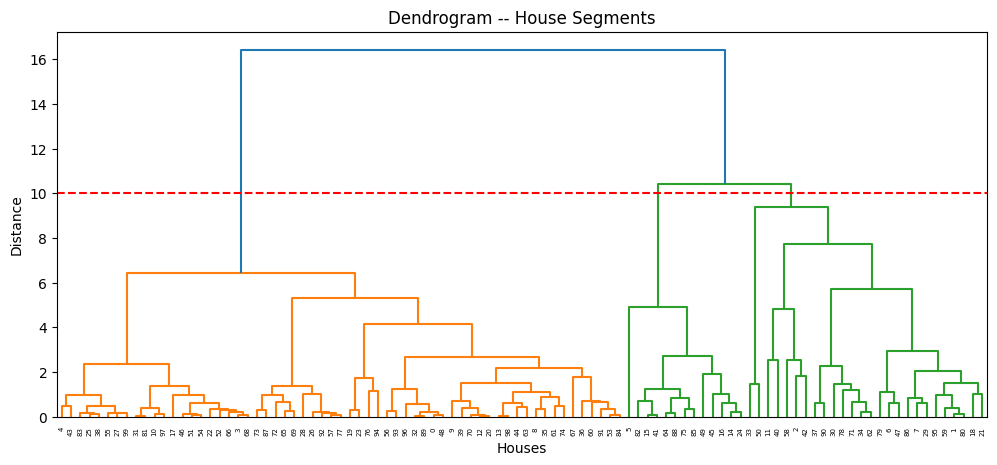

In [8]:
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(linked)
plt.title('Dendrogram -- House Segments')
plt.xlabel('Houses')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [9]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['HC_Cluster'] = hc.fit_predict(X_scaled)


In [10]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(2))

HC_Cluster
1    61
0    26
2    13
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           36407692.31      6.08   5.88       4.20
1            8306557.38      2.92   3.02       4.99
2           28784615.38      4.38   4.92      11.25
